# Part 1: Discrete Local Search

TODO this needs actual writeup

TODO time how long the approach takes

TODO at least one other algorithmic variant

In [53]:
from workload_data_loader import load_workload_instance

workload_28 = load_workload_instance("multi_resource_n28_m2.txt")
print(f"n = {workload_28[0]}")
print(f"m = {workload_28[1]}")
print(f"Utilities shape = {workload_28[2].shape}")
print(f"Demands shape = {workload_28[3].shape}")
print(f"Capacities shape = {workload_28[4].shape}")
print(f"Unconstrained maximum score = ", sum(workload_28[2]))

n = 28
m = 2
Utilities shape = (28,)
Demands shape = (2, 28)
Capacities shape = (2,)
Unconstrained maximum score =  164045.0


In [54]:
import numpy as np

# Explicit accessors for the workload data structure
def get_options(workload):
    return workload[0]

def get_resources(workload):
    return workload[1]

def get_utilities(workload):
    return workload[2]

def get_demands(workload):
    return workload[3]

def get_capacities(workload):
    return workload[4]

# Evaluates a given solution (an (n,1) vector) on a workload.
# Returns a boolean for solution validity, constrained utility (zero if resource limits exceeded), 
# unconstrained utility (utility if there were no resource limits), and resource usages
def evaluate(workload, solution):
    usage = np.dot(get_demands(workload), solution)
    utility = np.dot(get_utilities(workload), solution)
    valid_solution = not any([d > c for (d, c) in zip(usage, get_capacities(workload))])

    return valid_solution, utility if valid_solution else 0, utility, usage

print("----- Evaluation function -----")
print()
print("All zeros (guaranteed valid)  :", evaluate(workload_28, np.zeros(28)))
print("All ones (guaranteed invalid) :", evaluate(workload_28, np.ones(28)))

----- Evaluation function -----

All zeros (guaranteed valid)  : (True, np.float64(0.0), np.float64(0.0), array([0., 0.]))
All ones (guaranteed invalid) : (False, 0, np.float64(164045.0), array([1125.,  995.]))


In [55]:
# Returns a random solution for the provided workload
def random_solution(workload, prop0 = 0.5):
    return np.random.choice([0, 1], get_options(workload), True, [prop0, 1 - prop0])

# Returns a directly adjactent neighbour of the provided solution. Flips one bit.
def neighbour(solution):
    idx = np.random.randint(0, len(solution))

    new_solution = np.copy(solution)
    new_solution[idx] = 0 if new_solution[idx] == 1 else 1

    return new_solution

demo_random_sol = random_solution(workload_28)
demo_neighbour = neighbour(demo_random_sol)
print("----- Neighbour function -----")
print()
print("initial random       :", demo_random_sol)
print("neighbour            :", demo_neighbour)
print()
print("absolute difference  :", np.abs(demo_random_sol - demo_neighbour))

----- Neighbour function -----

initial random       : [0 1 1 1 0 0 0 1 1 1 0 1 1 0 0 0 0 1 0 0 1 0 0 0 0 1 0 1]
neighbour            : [0 1 1 1 0 0 0 1 1 1 0 1 1 0 0 0 0 1 0 0 1 0 0 0 1 1 0 1]

absolute difference  : [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0]


In [56]:

# Very standard hill climber algorithm.
def hill_climb_base(workload, n):
    trace = []
    best_sol = random_solution(workload, 0.9)
    best_eval = evaluate(workload, best_sol)
    trace.append(best_eval[1])

    for _ in range(n):
        neig = neighbour(best_sol)
        neig_eval = evaluate(workload, neig)
        if neig_eval[1] >= best_eval[1]:
            best_sol = neig
            best_eval = neig_eval

        trace.append(best_eval[1])

    return best_sol, best_eval, trace


# Applies n mutations by recursively calling the neighbour function
def recursive_neighbour(solution, n = 0):
    if n <= 0:
        return solution
    else:
        return recursive_neighbour(neighbour(solution), n - 1)

# Modified hill climber algorithm.
# Each time the algorithm lands on a worse solution after mutation, the algorithm will increase the 
# number of applied mutations for the next iteration. This should encourage more vigorous exploration
# when stuck in small local minima. Logarithmic scaling was found to perform better than linear scaling.
def hill_climb_escape_minima(workload, n):
    trace = []
    best_sol = random_solution(workload, 0.9)
    best_eval = evaluate(workload, best_sol)
    n_failures = 0
    trace.append(best_eval[1])

    for _ in range(n):
        neig = recursive_neighbour(best_sol, np.log2(n_failures + 1) + 1)
        neig_eval = evaluate(workload, neig)
        if neig_eval[1] >= best_eval[1]:
            best_sol = neig
            best_eval = neig_eval
            n_failures = 0
        else:
            n_failures += 1

        trace.append(best_eval[1])

    return best_sol, best_eval, trace

In [57]:
np.random.seed(42)

PART_1_RUNS = 1000
PART_1_ITERATIONS = 250

runs_base = [hill_climb_base(workload_28, PART_1_ITERATIONS) for _ in range(PART_1_RUNS)]
runs_minim = [hill_climb_escape_minima(workload_28, PART_1_ITERATIONS) for _ in range(PART_1_RUNS)]

traces_base = [run[2] for run in runs_base]
traces_minim = [run[2] for run in runs_minim]

best_base = [run[1][1] for run in runs_base]
best_minim = [run[1][1] for run in runs_minim]

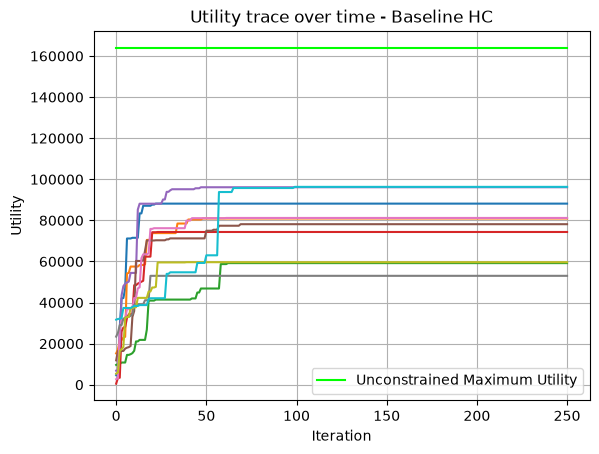

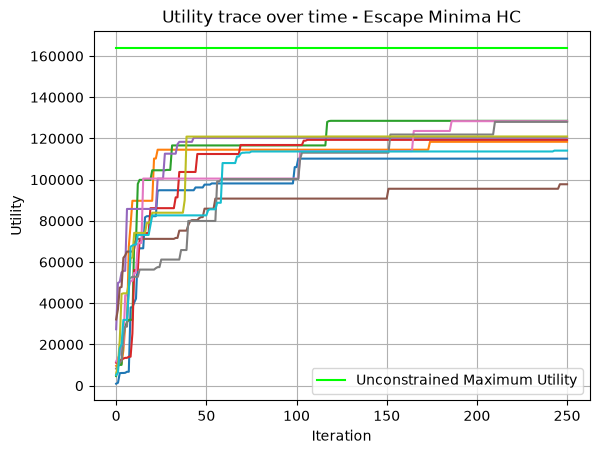

In [58]:
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

unconstrained_max = sum(get_utilities(workload_28))

for trace in traces_base[0:10]:
    plt.plot(trace)

plt.plot([unconstrained_max] * (PART_1_ITERATIONS + 1), color="lime", label="Unconstrained Maximum Utility")

plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title("Utility trace over time - Baseline HC")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


for trace in traces_minim[0:10]:
    plt.plot(trace)
    
plt.plot([unconstrained_max] * (PART_1_ITERATIONS + 1), color="lime", label="Unconstrained Maximum Utility")

plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title("Utility trace over time - Escape Minima HC")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

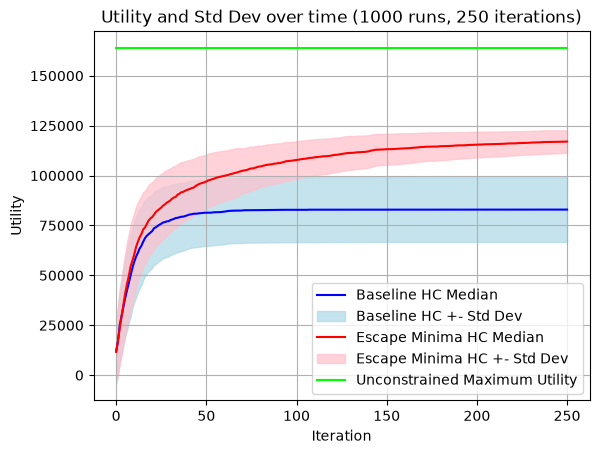

In [59]:
%matplotlib inline

base_median = np.median(traces_base, axis=0)
minim_median = np.median(traces_minim, axis=0)

base_std = np.std(traces_base, axis=0)
minim_std = np.std(traces_minim, axis=0)


plt.plot(base_median, color="blue", label="Baseline HC Median")
plt.fill_between(range(PART_1_ITERATIONS + 1), base_median - base_std, base_median + base_std, color="lightblue", alpha=0.7, label="Baseline HC +- Std Dev")

plt.plot(minim_median, color="red", label="Escape Minima HC Median")
plt.fill_between(range(PART_1_ITERATIONS + 1), minim_median - minim_std, minim_median + minim_std, color="pink", alpha=0.7, label="Escape Minima HC +- Std Dev")

unconstrained_max = sum(get_utilities(workload_28))
plt.plot([unconstrained_max] * (PART_1_ITERATIONS + 1), color="lime", label="Unconstrained Maximum Utility")

plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title(f"Utility and Std Dev over time ({PART_1_RUNS} runs, {PART_1_ITERATIONS} iterations)")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

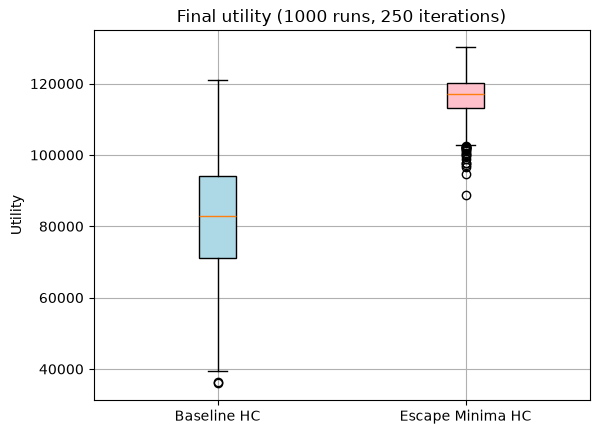

In [60]:

%matplotlib inline

np.random.seed(42)

bplot = plt.boxplot([best_base, best_minim], patch_artist=True, tick_labels=['Baseline HC', 'Escape Minima HC'])
for patch, colour in zip(bplot["boxes"], ["lightblue", "pink"]):
    patch.set_facecolor(colour)

plt.title(f"Final utility ({PART_1_RUNS} runs, {PART_1_ITERATIONS} iterations)")
plt.ylabel("Utility")
plt.grid(True)
plt.show()

# Part 2: Advanced Metaheuristic Engineering

TODO what approach? simulated annealing? go through lecture slides again for approach ideas

In [61]:
workload_90 = load_workload_instance("multi_resource_n90_m5.txt")
print(f"n = {workload_90[0]}")
print(f"m = {workload_90[1]}")
print(f"Utilities shape = {workload_90[2].shape}")
print(f"Demands shape = {workload_90[3].shape}")
print(f"Capacities shape = {workload_90[4].shape}")

n = 90
m = 5
Utilities shape = (90,)
Demands shape = (5, 90)
Capacities shape = (5,)


# Part 3: Empirical Study and Hypothesis Testing